# MacBERT Fine-tuning for Comment Moderation

## Experiment E2
- Base Model: hfl/chinese-macbert-base
- Dataset: COLD
- Task: Binary Classification
- Labels: Safe (0), Offensive (1)
- Training: train.csv
- Validation: dev.csv
- Test: test.csv

In [1]:
import torch
import pandas as pd
import numpy as np

import transformers
import sklearn
from pathlib import Path
from transformers import (AutoTokenizer, AutoModelForSequenceClassification)

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Scikit-learn:", sklearn.__version__)

# =====================================
# 2. Device
# =====================================
if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)



# =====================================
# 3. Model
MODEL_NAME = "hfl/chinese-macbert-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print("Tokenizer loaded successfully!'\n\n")



# =====================================
# 4. Load Classification Model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,  num_labels=2,      # num_labels=2：输出维度为 2，对应二分类
    # 这两个参数会被写进模型的 config，只是标签元数据（便于保存/展示时把 0/1 映射成 Safe/Offensive）。
    # 它不会改变 logits 的顺序，也不会自动把模型输出转成字符串
    id2label={0: "Safe",  1: "Offensive"},  label2id={"Safe": 0,  "Offensive": 1}
)

print("'\n\n'Model loaded successfully!")
print("Model parameters:",  sum(p.numel() for p in model.parameters()))

/opt/miniconda3/envs/CommentModeration/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.15.0
Transformers: 5.23.0
Scikit-learn: 1.9.1
Device: mps
Tokenizer loaded successfully!'




W1122 13:42:48.027000 1324 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 55819.33it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: hfl/chinese-macbert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                        

'

'Model loaded successfully!
Model parameters: 102269186


In [2]:
# =====================================
# 5. Load COLD Dataset
DATA_DIR = Path("../data/raw/COLDataset/COLDataset")
train_df = pd.read_csv(DATA_DIR / "train.csv", encoding="utf-8-sig",)
dev_df = pd.read_csv(DATA_DIR / "dev.csv", encoding="utf-8-sig",)

# 清理文本
for df in [train_df, dev_df]:
    df["TEXT"] = (df["TEXT"].fillna("").astype(str).str.strip())
    df["label"] = df["label"].astype(int)

# 检查数据
print("Train:", train_df.shape)
print("Dev:", dev_df.shape)

print("\nTrain labels:")
print(train_df["label"].value_counts())

print("\nDev labels:")
print(dev_df["label"].value_counts())

assert set(train_df["label"].unique()) <= {0, 1}
assert set(dev_df["label"].unique()) <= {0, 1}

print("\nDataset loaded successfully!")

Train: (25726, 5)
Dev: (6431, 5)

Train labels:
label
0    13003
1    12723
Name: count, dtype: int64

Dev labels:
label
0    3220
1    3211
Name: count, dtype: int64

Dataset loaded successfully!


In [3]:
# =====================================
# 6. Analyze Token Length

def get_token_lengths(texts, batch_size=256):
    lengths = []

    for start in range(0, len(texts), batch_size):
        batch = texts.iloc[start:start + batch_size].tolist()
        encoded = tokenizer(batch, add_special_tokens=True, truncation=False, padding=False)

        lengths.extend([len(ids) for ids in encoded["input_ids"]])

    return np.array(lengths)


train_lengths = get_token_lengths(train_df["TEXT"])
dev_lengths = get_token_lengths(dev_df["TEXT"])


# 统计长度分布
print("Train Token Length")
print(pd.Series(train_lengths).describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]))

print("\nDev Token Length")
print(pd.Series(dev_lengths).describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]))

Train Token Length
count    25726.000000
mean        49.124038
std         30.347968
min          5.000000
50%         42.000000
75%         68.000000
90%         98.000000
95%        110.000000
99%        123.000000
max        193.000000
dtype: float64

Dev Token Length
count    6431.000000
mean       48.624475
std        30.463894
min         6.000000
50%        41.000000
75%        67.000000
90%        98.000000
95%       111.000000
99%       122.000000
max       192.000000
dtype: float64


In [4]:
# =====================================
# 7. Truncation Analysis   计算不同长度下的截断比例

limits = [128, 256, 384, 512]

for limit in limits:
    truncated = np.sum(train_lengths > limit)
    percentage = truncated / len(train_lengths) * 100

    print(f"Max Length {limit}: "
          f"{truncated} comments truncated "
          f"({percentage:.2f}%)")

Max Length 128: 64 comments truncated (0.25%)
Max Length 256: 0 comments truncated (0.00%)
Max Length 384: 0 comments truncated (0.00%)
Max Length 512: 0 comments truncated (0.00%)


In [5]:
# =====================================
# 8. Build PyTorch Dataset
from torch.utils.data import Dataset, DataLoader

MAX_LENGTH = 256

class CommentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer):
        self.encodings = tokenizer(
            texts.tolist(), truncation=True,    # truncation=True：开启截断，超过`MAX_LENGTH`的句子会被截断
            max_length=MAX_LENGTH,  padding=False
        )
        self.labels = labels.tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {}
        for key, value in self.encodings.items():
            item[key] = value[idx]

        item["labels"] = self.labels[idx]

        return item


# 创建 Dataset
train_dataset = CommentDataset(
    train_df["TEXT"], train_df["label"], tokenizer)

dev_dataset = CommentDataset(
    dev_df["TEXT"],  dev_df["label"],  tokenizer)

print("Train Dataset:", len(train_dataset))
print("Dev Dataset:", len(dev_dataset))

Train Dataset: 25726
Dev Dataset: 6431


In [6]:
# =====================================
# 9. Build DataLoader

BATCH_SIZE = 16
SEED = 42

def collate_fn(batch):
    # print("Batch 类型:", type(batch))
    # print("Batch 长度:", len(batch))
    # for idx, item in enumerate(batch):
    #     print(f"\n第 {idx + 1} 条评论:")
    #     print(item)

    # 1. 提取批次内所有标签，转为长整型张量
    labels = torch.tensor([item["labels"] for item in batch],  dtype=torch.long)

    # 2. 提取批次内所有样本的输入特征（移除labels字段）
    features = [{key: value  for key, value in item.items()  if key != "labels"} for item in batch]
    
    # 3. 按批次内最长句子做填充，返回PyTorch张量
    padded = tokenizer.pad(features, padding=True, return_tensors="pt")
    padded["labels"] = labels

    return padded


generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,   #shuffle=True：训练集打乱样本顺序，避免样本顺序影响模型训练，提升泛化能力；验证集不打乱，保证评估结果稳定可复现
    collate_fn=collate_fn,  # `collate_fn=collate_fn`：传入自定义的批次整理函数，实现动态填充
    num_workers=0, generator=generator # 提高模型复用性
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)


print("Train batches:", len(train_loader))
print("Dev batches:", len(dev_loader), '\n\n')


# 查看一个 Batch
sample_batch = next(iter(train_loader))
for key, value in sample_batch.items():
    print(key, value.shape)

Train batches: 1608
Dev batches: 402 


input_ids torch.Size([16, 113])
token_type_ids torch.Size([16, 113])
attention_mask torch.Size([16, 113])
labels torch.Size([16])


In [7]:
# =====================================
# 10. Training Configuration

import random
from torch.optim import AdamW
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix)


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


EPOCHS = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

# 将模型放到 MPS
model = model.to(device)

# Optimizer
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

# Learning Rate Scheduler
total_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * 0.1)  # Warmup：训练初期逐渐提高学习率，减少初期参数更新不稳定的问题


def lr_lambda(current_step):
    if current_step < warmup_steps:
        return current_step / max(1, warmup_steps)

    return max(0.0, (total_steps - current_step) / max(1, total_steps - warmup_steps))


scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

print("Training steps:", total_steps)
print("Warmup steps:", warmup_steps)
print("Device:", device)

Training steps: 4824
Warmup steps: 482
Device: mps


In [8]:
# =====================================
# 11. Evaluation Function

def evaluate(model, dataloader):
    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for batch in dataloader:
            labels = batch["labels"]

            inputs = {key: value.to(device) for key, value in batch.items() if key != "labels"}
            outputs = model(**inputs)

            predictions = torch.argmax(outputs.logits, dim=-1)
            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())

    accuracy = accuracy_score(all_labels, all_predictions)
    macro_f1 = f1_score(all_labels, all_predictions, average="macro")
    offensive_precision = precision_score(all_labels, all_predictions, pos_label=1, zero_division=0)
    offensive_recall = recall_score(all_labels, all_predictions, pos_label=1, zero_division=0)

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "offensive_precision": offensive_precision,
        "offensive_recall": offensive_recall,
        "predictions": all_predictions,
        "labels": all_labels
    }

In [9]:
# =====================================
# 12. Fine-tuning MacBERT

from pathlib import Path
BEST_MODEL_DIR = (Path.cwd().parent / "models" / "macbert_cold_best")
BEST_MODEL_DIR.mkdir(parents=True, exist_ok=True)

best_macro_f1 = -1
training_history = []

for epoch in range(EPOCHS):
    print("\n" + "=" * 60)
    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print("=" * 60)

    model.train()
    total_loss = 0

    for step, batch in enumerate(train_loader):
        labels = batch["labels"].to(device)  # 获取标签
        inputs = {key: value.to(device) for key, value in batch.items() if key != "labels"}  # 获取模型输入
        optimizer.zero_grad(set_to_none=True)    # 清空梯度

        outputs = model(**inputs, labels=labels)  # Forward
        loss = outputs.loss
        loss.backward()  # Backward

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # Gradient Clipping

        optimizer.step()  # 更新参数
        scheduler.step()  # 更新学习率
        total_loss += loss.item()

        if (step + 1) % 200 == 0:
            print(f"Step [{step + 1}/{len(train_loader)}] " f"Loss: {loss.item():.4f}")

    avg_loss = total_loss / len(train_loader)
    metrics = evaluate(model, dev_loader)  # Validation

    print("\nTraining Loss:", round(avg_loss, 4))
    print("Validation Accuracy:", round(metrics["accuracy"], 4))
    print("Validation Macro F1:", round(metrics["macro_f1"], 4))
    print("Offensive Precision:", round(metrics["offensive_precision"], 4))
    print("Offensive Recall:", round(metrics["offensive_recall"], 4))

    training_history.append({
        "epoch": epoch + 1,
        "train_loss": avg_loss,
        "accuracy": metrics["accuracy"],
        "macro_f1": metrics["macro_f1"],
        "offensive_precision": metrics["offensive_precision"],
        "offensive_recall": metrics["offensive_recall"]
    })

    # 保存最佳模型
    if metrics["macro_f1"] > best_macro_f1:
        best_macro_f1 = metrics["macro_f1"]
        model.save_pretrained(str(BEST_MODEL_DIR))
        tokenizer.save_pretrained(str(BEST_MODEL_DIR))
        print("Best model saved!")

    print("\nBest Macro F1:", round(best_macro_f1, 4))

print("\nTraining completed!")


Epoch 1/3
Step [200/1608] Loss: 0.3891
Step [400/1608] Loss: 0.2126
Step [600/1608] Loss: 0.0385
Step [800/1608] Loss: 0.4435
Step [1000/1608] Loss: 0.0979
Step [1200/1608] Loss: 0.8158
Step [1400/1608] Loss: 0.1020
Step [1600/1608] Loss: 0.2473

Training Loss: 0.3065
Validation Accuracy: 0.9218
Validation Macro F1: 0.9217
Offensive Precision: 0.9011
Offensive Recall: 0.9474


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.01it/s]


Best model saved!

Best Macro F1: 0.9217

Epoch 2/3
Step [200/1608] Loss: 0.2416
Step [400/1608] Loss: 0.2103
Step [600/1608] Loss: 0.0855
Step [800/1608] Loss: 0.2716
Step [1000/1608] Loss: 0.3669
Step [1200/1608] Loss: 0.0125
Step [1400/1608] Loss: 0.1594
Step [1600/1608] Loss: 0.0282

Training Loss: 0.1669
Validation Accuracy: 0.9308
Validation Macro F1: 0.9308
Offensive Precision: 0.9325
Offensive Recall: 0.9287


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  5.05it/s]


Best model saved!

Best Macro F1: 0.9308

Epoch 3/3
Step [200/1608] Loss: 0.2017
Step [400/1608] Loss: 0.0105
Step [600/1608] Loss: 0.0012
Step [800/1608] Loss: 0.1641
Step [1000/1608] Loss: 0.0034
Step [1200/1608] Loss: 0.0038
Step [1400/1608] Loss: 0.0033
Step [1600/1608] Loss: 0.1771

Training Loss: 0.1007
Validation Accuracy: 0.9303
Validation Macro F1: 0.9303
Offensive Precision: 0.9268
Offensive Recall: 0.9343

Best Macro F1: 0.9308

Training completed!


In [ ]:
# =====================================
# Load Saved MacBERT

import torch
from transformers import (AutoTokenizer, AutoModelForSequenceClassification)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

# 加载之前训练好的模型
tokenizer = AutoTokenizer.from_pretrained(str(BEST_MODEL_DIR))
model = AutoModelForSequenceClassification.from_pretrained(str(BEST_MODEL_DIR)).to(device)
model.eval()

print("Saved MacBERT loaded successfully!")
print("Device:", device)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 9726.17it/s]


Saved MacBERT loaded successfully!
Device: mps


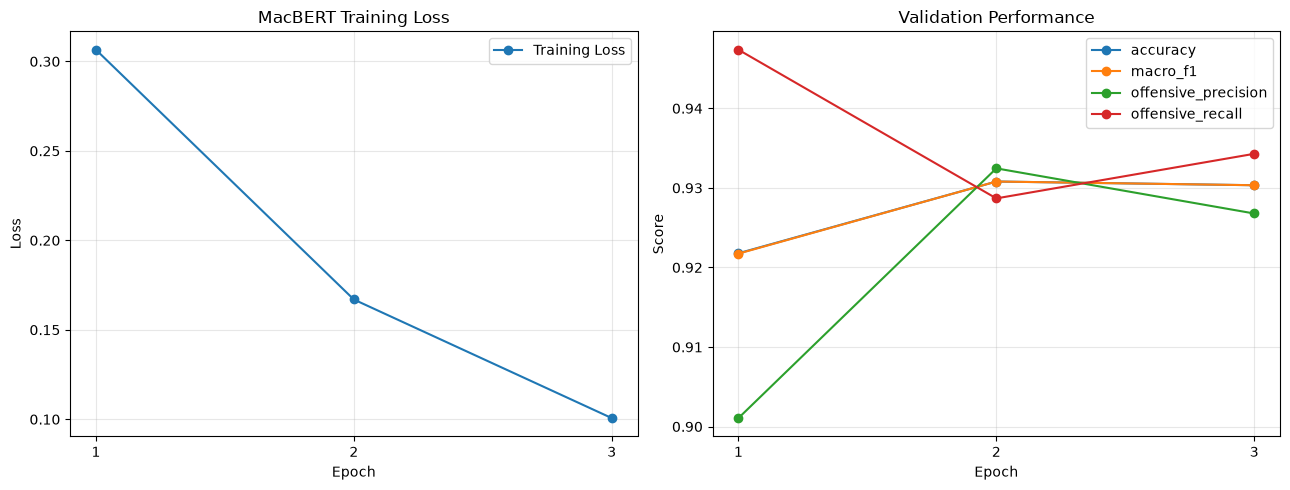

In [ ]:
import matplotlib.pyplot as plt

history_df = pd.DataFrame(training_history)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Training Loss
axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Training Loss")

axes[0].set_title("MacBERT Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks([1, 2, 3])
axes[0].grid(alpha=0.3)
axes[0].legend()

# Validation Metrics
for metric in ["accuracy", "macro_f1", "offensive_precision", "offensive_recall"]:
    axes[1].plot(history_df["epoch"], history_df[metric], marker="o", label=metric)

axes[1].set_title("Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_xticks([1, 2, 3])
axes[1].grid(alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 25196.66it/s]


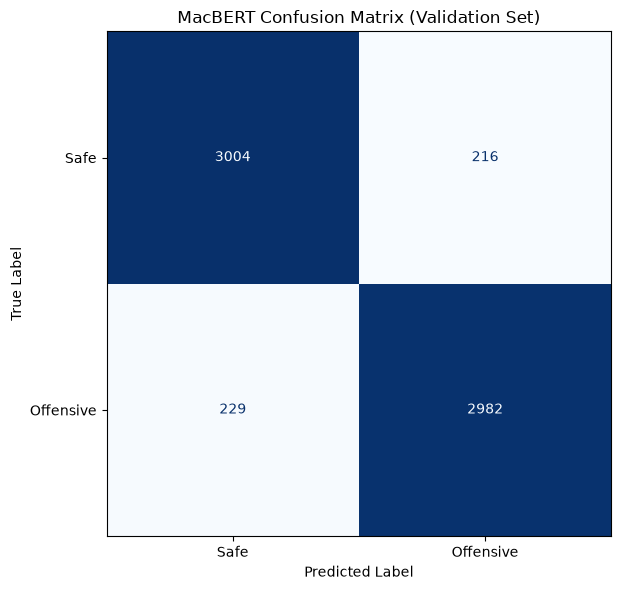

              precision    recall  f1-score   support

        Safe     0.9292    0.9329    0.9310      3220
   Offensive     0.9325    0.9287    0.9306      3211

    accuracy                         0.9308      6431
   macro avg     0.9308    0.9308    0.9308      6431
weighted avg     0.9308    0.9308    0.9308      6431



In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from transformers import AutoModelForSequenceClassification  # 1. 加载之前保存的最佳模型

best_model = AutoModelForSequenceClassification.from_pretrained(str(BEST_MODEL_DIR)).to(device)

# 2. 在验证集上进行预测
metrics = evaluate(best_model, dev_loader)
y_true = metrics["labels"]
y_pred = metrics["predictions"]

# 3. 计算混淆矩阵
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

# 4. 可视化
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Safe", "Offensive"])
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

plt.title("MacBERT Confusion Matrix (Validation Set)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# 6. 输出分类报告
print(classification_report(y_true, y_pred, labels=[0, 1], target_names=["Safe", "Offensive"], digits=4, zero_division=0))

In [13]:
# =====================================
# 14. Load Test Dataset

test_df = pd.read_csv(DATA_DIR / "test.csv", encoding="utf-8-sig")
test_df["TEXT"] = (test_df["TEXT"].fillna("").astype(str).str.strip())
test_df["label"] = test_df["label"].astype(int)

test_dataset = CommentDataset(test_df["TEXT"], test_df["label"], tokenizer)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, num_workers=0)

print("Test samples:", len(test_dataset))
print("Test batches:", len(test_loader))

Test samples: 5323
Test batches: 333


In [14]:
# =====================================
# 15. Final Test Evaluation

best_model = AutoModelForSequenceClassification.from_pretrained(str(BEST_MODEL_DIR)).to(device)
test_metrics = evaluate(best_model, test_loader)

print("\nTEST RESULT")
print(classification_report(test_metrics["labels"], test_metrics["predictions"], target_names=["Safe", "Offensive"], digits=4))

cm = confusion_matrix(test_metrics["labels"], test_metrics["predictions"])
print("Confusion Matrix:")
print(cm)


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 26772.15it/s]



TEST RESULT
              precision    recall  f1-score   support

        Safe     0.8969    0.7951    0.8429      3216
   Offensive     0.7334    0.8605    0.7919      2107

    accuracy                         0.8210      5323
   macro avg     0.8151    0.8278    0.8174      5323
weighted avg     0.8322    0.8210    0.8227      5323

Confusion Matrix:
[[2557  659]
 [ 294 1813]]


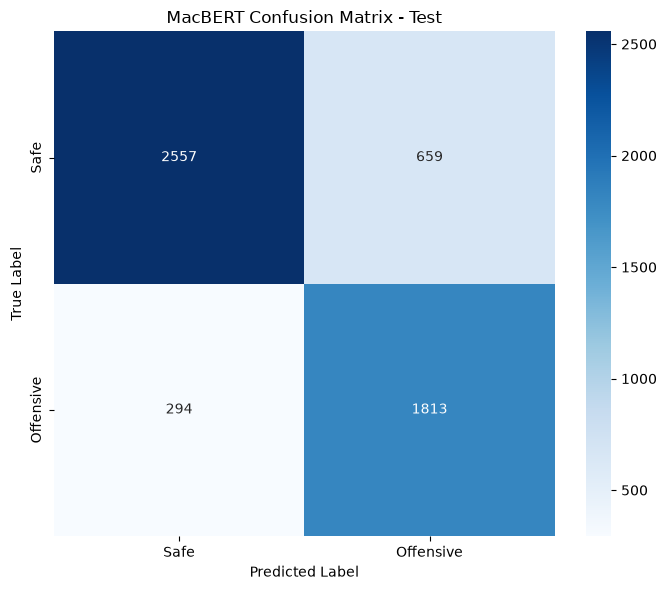

In [ ]:
import seaborn as sns

plt.figure(figsize=(7, 6))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Safe", "Offensive"], yticklabels=["Safe", "Offensive"])

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("MacBERT Confusion Matrix - Test")
plt.tight_layout()
plt.show()

In [16]:
# =====================================
# Save Test Results

import json
from sklearn.metrics import classification_report

report = classification_report(test_metrics["labels"],  test_metrics["predictions"], target_names=["Safe", "Offensive"], output_dict=True)
with open("../models/macbert_cold_best/config.json", "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=4)


# 保存混淆矩阵
cm = confusion_matrix(test_metrics["labels"], test_metrics["predictions"])

pd.DataFrame(cm, index=["True Safe", "True Offensive"], columns=["Pred Safe", "Pred Offensive"]).to_csv("../models/macbert_cold_best/macbert_test_confusion_matrix.csv")

# 保存预测结果，方便以后分析误分类
pd.DataFrame({"text": test_df["TEXT"], "true_label": test_metrics["labels"], "predicted_label": test_metrics["predictions"]}).to_csv(
    "../models/macbert_cold_best/macbert_test_predictions.csv", index=False, encoding="utf-8-sig"
)

print("Test results saved!")

Test results saved!


In [19]:
# =====================================
# 16. Save Test Predictions and Results

import json
import numpy as np
import pandas as pd

RESULT_DIR = Path("../results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

best_model.eval()
all_probabilities = []

with torch.no_grad():
    for batch in test_loader:
        inputs = {
            key: value.to(device)
            for key, value in batch.items()
            if key != "labels"
        }

        outputs = best_model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=-1)[:, 1]
        all_probabilities.extend(probabilities.cpu().numpy())

all_probabilities = np.array(all_probabilities)
predictions = (all_probabilities >= 0.5).astype(int)

# 保存每条评论的预测结果
prediction_df = pd.DataFrame({
    "text": test_df["TEXT"],
    "true_label": test_df["label"],
    "predicted_label": predictions,
    "offensive_probability": all_probabilities
})

prediction_df["error_type"] = np.select(
    [(prediction_df["true_label"] == 0) & (prediction_df["predicted_label"] == 1), (prediction_df["true_label"] == 1) & (prediction_df["predicted_label"] == 0)],
    ["False Positive", "False Negative"],
    default="Correct"
)

prediction_df.to_csv(RESULT_DIR / "macbert_test_predictions.csv", index=False, encoding="utf-8-sig")

print("Test predictions saved!")
print(prediction_df["error_type"].value_counts())

Test predictions saved!
error_type
Correct           4370
False Positive     659
False Negative     294
Name: count, dtype: int64
